# S5 · Social-dilemma game and cooperation over time

This notebook describes the game data and how giving changed during the
session, overall, by friendship type and by classroom size. Code:
`code/si/S5_game_and_time.R`. (The classroom bootstrap with 4,999 draws
takes about half a minute.)

In [ ]:
here::i_am("notebooks/si/S5_game_and_time.qmd")
source(here::here("code", "00_helpers.R"))
source(here("code", "00_style.R"))
source(here("code", "si", "figures", "S5_figures.R"))   # plotting functions of this section
library(patchwork)
dir.create(here("output", "figures", "si"), recursive = TRUE, showWarnings = FALSE)

dyads <- read_csv(here("data", "generated", "analysis_dyads.csv"), show_col_types = FALSE)

save_si_figure <- function(plot, name, width, height) {
  ggsave(here("output", "figures", "si", paste0(name, ".pdf")), plot, width = width, height = height)
  ggsave(here("output", "figures", "si", paste0(name, ".png")), plot, width = width, height = height, dpi = 300)
}

## When did each decision happen?

In [ ]:
# Three ways of saying "when" a decision happened:
#   round           the classroom round of the matching schedule
#   decision_order  1st, 2nd, ... decision of this child (children skip
#                   rounds in which they have no partner)
#   progress        (order - 1) / (number of decisions - 1), from 0 to 1
# plus the classroom size and three friendship groups.

dyads <- dyads %>%
  group_by(class_id) %>%
  mutate(class_size = n_distinct(sender_id)) %>%
  group_by(sender_id) %>%
  arrange(round, .by_group = TRUE) %>%
  mutate(decision_order = row_number(),
         progress       = (decision_order - 1) / (n() - 1),
         fifth          = pmin(pmax(ceiling(progress * 5), 1), 5)) %>%   # 0 counts in the first fifth
  ungroup() %>%
  mutate(friend_group = case_when(friendship == "Mutual"      ~ "Mutual friends",
                                  friendship == "Non-friends" ~ "Non-friends",
                                  TRUE                        ~ "Asymmetric ties"),
         friend_group = factor(friend_group, levels = c("Non-friends", "Asymmetric ties", "Mutual friends")))

## Table S11. Matching schedule (A) and temporal trends (B)

### Panel A. Matching schedule and participation

In [ ]:
# Table S11, Panel A
describe <- function(x, unit) {
  tibble(unit = unit, n = length(x), mean = mean(x), sd = sd(x), median = median(x),
         range = paste0(min(x), "-", max(x)))
}

table_s11_a <- bind_rows(
  describe(dyads %>% group_by(class_id) %>% summarise(r = n_distinct(round)) %>% pull(r),
           "Recorded matching rounds per classroom"),
  describe(dyads %>% count(sender_id) %>% pull(n), "Directed decisions per participant"),
  describe(dyads %>% distinct(class_id, class_size) %>% pull(class_size), "Participants per classroom")
)

table_s11_a

unit,n,mean,sd,median,range
Recorded matching rounds per classroom,45,23.93333,7.243806,23,7-43
Directed decisions per participant,859,20.72643,7.444019,20,6-38
Participants per classroom,45,19.08889,7.175787,18,7-39


### Panel B. Linear trends in tokens sent

In [ ]:
# Table S11, Panel B: linear trends in tokens sent. All standard errors are
# clustered by classroom; class size is centered at 18 in the interactions.
dyads <- dyads %>%
  mutate(size_18 = class_size - 18,
         across(c(sender_id, receiver_id, class_id), as.factor, .names = "{.col}_f"))

trend <- function(formula, data = dyads) felm(as.formula(formula), data = data)

temporal_models <- list(
  "Absolute round, unadjusted"         = trend("tokens_sent ~ round | 0 | 0 | class_id"),
  "Absolute round + class size"        = trend("tokens_sent ~ round + class_size | 0 | 0 | class_id"),
  "Absolute round + classroom FE"      = trend("tokens_sent ~ round | class_id_f | 0 | class_id"),
  "Absolute round + sender and partner FE" = trend("tokens_sent ~ round | sender_id_f + receiver_id_f | 0 | class_id"),
  "Rounds 1-7 + sender and partner FE" = trend("tokens_sent ~ round | sender_id_f + receiver_id_f | 0 | class_id",
                                               data = filter(dyads, round <= 7)),
  "Relative progress + sender and partner FE" = trend("tokens_sent ~ progress | sender_id_f + receiver_id_f | 0 | class_id"),
  "Relative progress x class size"     = trend("tokens_sent ~ progress * size_18 | sender_id_f + receiver_id_f | 0 | class_id"),
  "Absolute round x class size"        = trend("tokens_sent ~ round * size_18 | sender_id_f + receiver_id_f | 0 | class_id")
)

table_s11_b <- imap_dfr(temporal_models, function(model, name) {
  summary(model)$coefficients %>%
    as_tibble(rownames = "term") %>%
    filter(term != "(Intercept)", !is.nan(Estimate)) %>%   # main effect of size is absorbed by the FE
    transmute(specification = name, term, estimate = Estimate,
              se = `Cluster s.e.`, p_value = `Pr(>|t|)`, n = model$N)
})

table_s11_b %>% mutate(across(where(is.double), ~ round(.x, 4)))

specification,term,estimate,se,p_value,n
"Absolute round, unadjusted",round,0.0167,0.0072,0.0199,17804
Absolute round + class size,round,0.0297,0.0068,0.0000,17804
Absolute round + class size,class_size,-0.0426,0.0221,0.0537,17804
Absolute round + classroom FE,round,0.0299,0.0065,0.0000,17804
Absolute round + sender and partner FE,round,0.0294,0.0066,0.0001,17804
Rounds 1-7 + sender and partner FE,round,0.1109,0.0263,0.0001,4704
Relative progress + sender and partner FE,progress,0.8922,0.1364,0.0000,17804
Relative progress x class size,progress,0.9866,0.1270,0.0000,17804
Relative progress x class size,progress:size_18,-0.0151,0.0154,0.3312,17804
Absolute round x class size,round,0.0487,0.0061,0.0000,17804


## Table S12 and Figure S9. Game behavior

In [ ]:
# Table S12. Directed decisions for tokens and GAP; one row per unordered
# pair for the difference between the two allocations.
pairs <- dyads %>% filter(sender_id_f != receiver_id_f, as.numeric(as.character(sender_id)) < as.numeric(as.character(receiver_id)))

table_s12 <- tribble(
  ~quantity,                        ~n,             ~mean,                                    ~sd,                                    ~median,
  "Tokens sent",                    nrow(dyads),    mean(dyads$tokens_sent),                  sd(dyads$tokens_sent),                  median(dyads$tokens_sent),
  "Absolute reciprocal difference", nrow(pairs),    mean(abs(pairs$coop_gap)),                sd(abs(pairs$coop_gap)),                median(abs(pairs$coop_gap)),
  "Observed Cooperation GAP",       nrow(dyads),    mean(dyads$coop_gap),                     sd(dyads$coop_gap),                     median(dyads$coop_gap)
)

table_s12

quantity,n,mean,sd,median
Tokens sent,17804,4.705122,3.743247,4
Absolute reciprocal difference,8902,3.567962,3.125333,3
Observed Cooperation GAP,17804,0.000000,4.743230,0


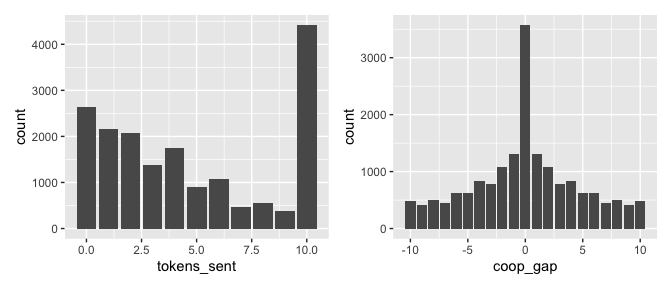

In [ ]:
# Figure S9: (A) tokens sent, (B) the two allocations of each pair,
# (C) the Cooperation GAP, with zero gaps in orange, (D) what zero gaps are made of
# Quick look: tokens sent and the Cooperation GAP
(ggplot(dyads, aes(tokens_sent)) + geom_bar()) |
  (ggplot(dyads, aes(coop_gap)) + geom_bar())

#### Supporting Information layout

Plotting code from `code/si/figures/S5_figures.R`. This is the version
saved to `output/figures/si/`.

In [ ]:
# Figure S9: (A) tokens sent, (B) the two allocations of each pair, (C) the
# Cooperation GAP with zero gaps in orange, (D) what the zero gaps are made of.
plot_figure_s9 <- function(dyads, pairs) {
  percent_axis <- scale_y_continuous(labels = function(x) paste0(x, "%"),
                                     expand = expansion(mult = c(0, 0.05)))

  panel_a <- dyads %>%
    count(tokens_sent) %>%
    mutate(percent = 100 * n / sum(n)) %>%
    ggplot(aes(tokens_sent, percent)) +
    geom_col(fill = color_slate, width = 0.8) +
    scale_x_continuous(breaks = 0:10) + percent_axis +
    labs(title = "A. Tokens sent", x = "Tokens sent", y = "Directed decisions (%)") +
    theme_si(9)

  pair_cells <- pairs %>%
    count(high = pmax(tokens_sent, tokens_received), low = pmin(tokens_sent, tokens_received)) %>%
    mutate(percent = 100 * n / sum(n))

  panel_b <- ggplot(pair_cells, aes(high, low, fill = percent)) +
    geom_tile(color = "white") +
    geom_text(aes(label = sprintf("%.1f", percent)), size = 1.9, fontface = "bold",
              color = if_else(pair_cells$percent > 8, "white", "grey15")) +
    scale_fill_gradientn(colors = c("#FFF4D0", "#F2C66D", "#E39A55", "#C95A3A"),
                         name = "% of interactions") +
    scale_x_continuous(breaks = 0:10, expand = c(0, 0)) +
    scale_y_continuous(breaks = 0:10, expand = c(0, 0)) +
    coord_fixed() +
    labs(title = "B. Bivariate token distribution",
         x = "Tokens sent from j to i", y = "Tokens sent from i to j") +
    theme_si(9) +
    theme(panel.grid = element_blank(), panel.border = element_blank(),
          legend.position = c(0.25, 0.85), legend.direction = "horizontal",
          legend.title.align = 0, legend.key.height = unit(2, "mm"),
          legend.title = element_text(face = "bold", size = 7), legend.text = element_text(size = 6)) +
    guides(fill = guide_colorbar(title.position = "top"))

  gap_bars <- dyads %>%
    mutate(kind = case_when(coop_gap == 0 & tokens_sent == 0 ~ "0-0",
                            coop_gap == 0                    ~ "Equal positive",
                            TRUE                             ~ "Unequal")) %>%
    count(coop_gap, kind) %>%
    mutate(percent = 100 * n / sum(n),
           kind = factor(kind, levels = c("Equal positive", "0-0", "Unequal")))

  panel_c <- ggplot(gap_bars, aes(coop_gap, percent, fill = kind)) +
    geom_col(width = 0.8) +
    scale_fill_manual(values = c("Equal positive" = color_highlight, "0-0" = "#E8A06E",
                                 Unequal = color_slate)) +
    scale_x_continuous(breaks = seq(-10, 10, 2)) + percent_axis +
    labs(title = "C. Cooperation GAP", x = "Tokens received - tokens sent",
         y = "Directed decisions (%)") +
    theme_si(9)

  zero_gap <- pairs %>%
    filter(coop_gap == 0) %>%
    mutate(friend_group = if_else(friendship %in% c("Sender declares", "Receiver declares"),
                                  "Asymmetric ties", as.character(friend_group)),
           friend_group = factor(friend_group, levels = c("Asymmetric ties", "Mutual friends", "Non-friends")))

  zero_bars <- zero_gap %>%
    count(tokens_sent, friend_group) %>%
    mutate(percent = 100 * n / nrow(zero_gap)) %>%
    group_by(tokens_sent) %>%
    mutate(share = 100 * n / sum(n)) %>%
    ungroup()

  share_zero <- 100 * mean(zero_gap$tokens_sent == 0)

  panel_d <- ggplot(zero_bars, aes(tokens_sent, percent, fill = friend_group)) +
    geom_col(width = 0.8, color = "white", linewidth = 0.2) +
    # share of each friendship type inside the tall columns
    geom_text(data = filter(zero_bars, percent > 6),
              aes(label = paste0(round(share), "%")), position = position_stack(vjust = 0.5),
              angle = 90, color = "white", fontface = "bold", size = 2.4) +
    annotate("segment", x = -0.4, xend = 0.4, y = 55, yend = 55, color = "#E8A06E", linewidth = 1) +
    annotate("segment", x = 0.6, xend = 10.4, y = 55, yend = 55, color = color_highlight, linewidth = 1) +
    annotate("text", x = 0, y = 59, size = 2.4, fontface = "bold", color = "#E8A06E",
             label = sprintf("0-0\n%.1f%%", share_zero)) +
    annotate("text", x = 5.5, y = 59, size = 2.4, fontface = "bold", color = color_highlight,
             label = sprintf("Equal positive\n%.1f%%", 100 - share_zero)) +
    scale_fill_manual(values = c("Non-friends" = "#9B86C9", "Mutual friends" = "#7FCDBB",
                                 "Asymmetric ties" = "#8FD3EC"), name = "Friendship type") +
    scale_x_continuous(breaks = 0:10) +
    scale_y_continuous(labels = function(x) paste0(x, "%"), breaks = c(0, 25, 50),
                       expand = expansion(mult = c(0, 0.02))) +
    coord_cartesian(ylim = c(0, 63)) +
    labs(title = "D. Zero GAP decomposition", x = "Tokens sent by both students",
         y = "Zero-GAP dyads (%)") +
    theme_si(9) +
    theme(legend.position = c(0.3, 0.6), legend.title = element_text(face = "bold", size = 8),
          legend.key.size = unit(3, "mm"), legend.text = element_text(size = 7))

  figure_s9 <- (panel_a | panel_b) / (panel_c | panel_d)
  figure_s9
}

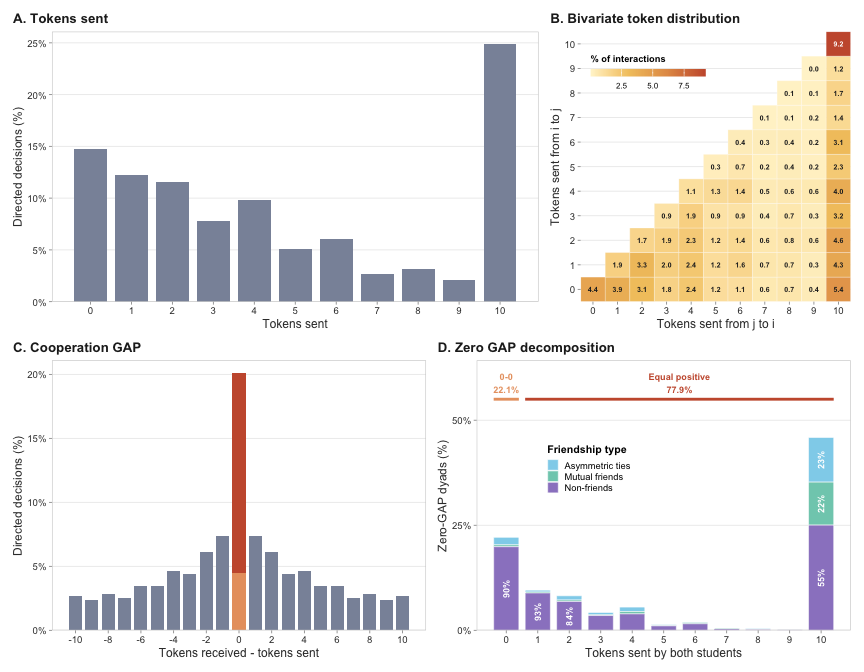

In [ ]:
# Supporting Information layout (plotting code in figures/S5_figures.R)
figure_s9 <- plot_figure_s9(dyads, pairs)
figure_s9

## Figure S10 and Table S13. Giving over the session

### Mean tokens sent in classroom rounds 1–7

In [ ]:
# Means with 95% confidence intervals, and the number of classrooms behind
# each point (used for point size)
mean_ci <- function(data, ...) {
  data %>%
    group_by(...) %>%
    summarise(mean = mean(tokens_sent), se = sd(tokens_sent) / sqrt(n()),
              classrooms = n_distinct(class_id), decisions = n(), .groups = "drop") %>%
    mutate(low = mean - 1.96 * se, high = mean + 1.96 * se)
}

by_round    <- mean_ci(dyads, round)
by_order    <- mean_ci(dyads, decision_order)
by_fifth    <- mean_ci(dyads, fifth)

by_round %>% filter(round <= 7)

round,mean,se,classrooms,decisions,low,high
1,3.822485,0.1189358,45,676,3.589371,4.055599
2,4.294985,0.1222957,45,678,4.055286,4.534685
3,4.406805,0.1290156,45,676,4.153934,4.659675
4,4.537202,0.1354363,45,672,4.271747,4.802657
5,4.550000,0.1331541,45,680,4.289018,4.810982
6,4.593168,0.1411613,45,644,4.316491,4.869844
7,4.587021,0.1335966,45,678,4.325171,4.848870


### Mean tokens sent by fifth of each child’s session

In [ ]:
by_fifth

fifth,mean,se,classrooms,decisions,low,high
1,4.262153,0.0542126,45,3929,4.155897,4.368410
2,4.610548,0.0635876,45,3356,4.485917,4.735180
3,4.712763,0.0648103,45,3377,4.585735,4.839791
4,4.906436,0.0669027,45,3356,4.775307,5.037566
5,5.063391,0.0640910,45,3786,4.937773,5.189010


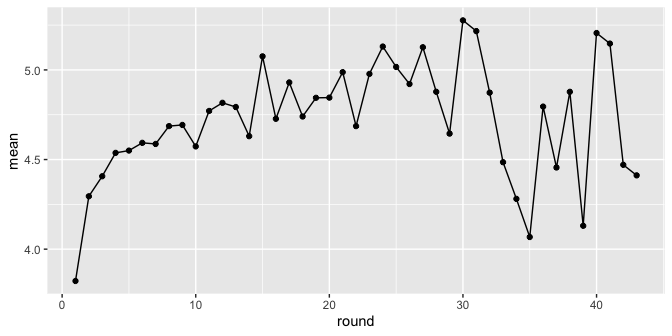

In [ ]:
# Quick look: mean tokens sent by classroom round
ggplot(by_round, aes(round, mean)) +
  geom_line() +
  geom_point()

#### Supporting Information layout

Plotting code from `code/si/figures/S5_figures.R`. This is the version
saved to `output/figures/si/`.

In [ ]:
# Figure S10: mean tokens sent by classroom round, rounds 1-7, personal
# decision order and personal session progress.
plot_figure_s10 <- function(by_round, by_order, by_fifth) {
  time_panel <- function(data, x, title, xlab) {
    ggplot(data, aes({{ x }}, mean)) +
      geom_ribbon(aes(ymin = low, ymax = high), fill = color_slate, alpha = 0.18) +
      geom_line(color = color_slate, linewidth = 0.6) +
      geom_point(aes(size = classrooms), color = color_slate) +
      scale_size_continuous(range = c(0.3, 1.8)) +
      labs(title = title, x = xlab, y = "Mean tokens sent") +
      theme_si(8)
  }

  figure_s10 <- (time_panel(by_round, round, "A. Mean tokens sent by classroom game round",
                            "Classroom game round") |
                 time_panel(filter(by_round, round <= 7), round, "B. Common-support rounds 1-7",
                            "Classroom game round") + scale_x_continuous(breaks = 1:7)) /
                (time_panel(by_order, decision_order, "C. Personal decision order",
                            "Personal decision order") +
                   geom_vline(xintercept = 6, linetype = "dotted", color = "grey60") +
                   scale_x_continuous(breaks = c(1, 6, 10, 20, 30, 38)) |
                 ggplot(by_fifth, aes(fifth, mean)) +
                   geom_line(color = color_slate, linewidth = 0.6) +
                   geom_errorbar(aes(ymin = low, ymax = high), width = 0.08, color = color_slate) +
                   geom_point(color = color_slate, size = 1.8) +
                   scale_x_continuous(breaks = 1:5, labels = progress_labels) +
                   labs(title = "D. Personal session progress", x = "Personal session progress",
                        y = "Mean tokens sent") +
                   theme_si(8)) +
    plot_annotation(title = "Giving over classroom game rounds and personal progress",
                    theme = theme(plot.title = element_text(face = "bold", hjust = 0.5)))
  figure_s10
}

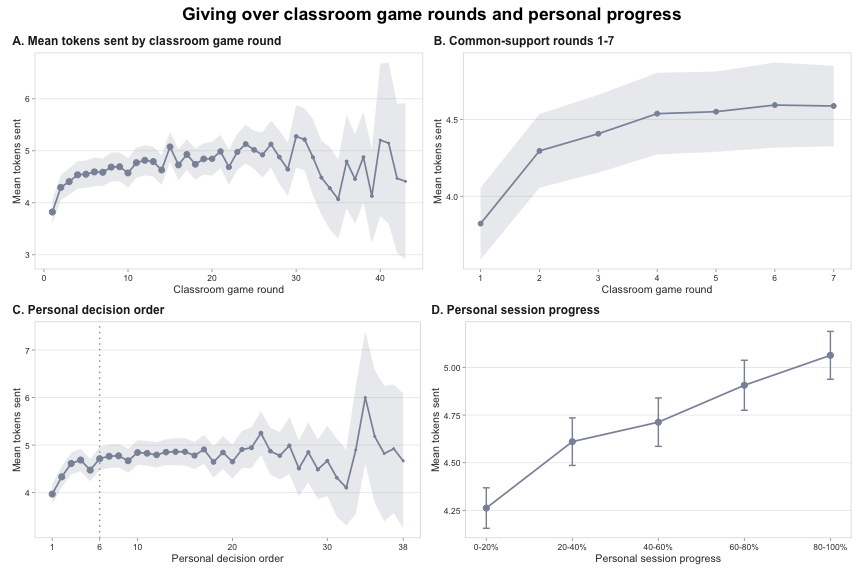

In [ ]:
# Supporting Information layout (plotting code in figures/S5_figures.R)
figure_s10 <- plot_figure_s10(by_round, by_order, by_fifth)
figure_s10

### Table S13. Classroom coverage by round

In [ ]:
# Table S13: how many classrooms have at least one decision in each round
coverage <- dyads %>%
  group_by(round) %>%
  summarise(classrooms = n_distinct(class_id)) %>%
  mutate(share = 100 * classrooms / 45)

coverage %>% group_by(classrooms, share) %>%
  summarise(rounds = paste0(min(round), "-", max(round)), .groups = "drop") %>%
  arrange(desc(classrooms))

classrooms,share,rounds
45,100.000000,1-7
44,97.777778,8-11
43,95.555556,12-13
41,91.111111,14-15
40,88.888889,16-17
39,86.666667,18-19
32,71.111111,20-21
27,60.000000,22-23
22,48.888889,24-25
14,31.111111,26-27


## Figure S11 and Table S14. By friendship type

### Mean tokens sent by friendship group in classroom rounds 1–2

In [ ]:
# Figure S11: the same four views, by friendship group
by_round_f <- mean_ci(dyads, round, friend_group)
by_order_f <- mean_ci(dyads, decision_order, friend_group)
by_fifth_f <- mean_ci(dyads, fifth, friend_group)

by_round_f %>% filter(round <= 2)

round,friend_group,mean,se,classrooms,decisions,low,high
1,Non-friends,3.785714,0.1361899,44,532,3.518782,4.052646
1,Asymmetric ties,3.576087,0.2821466,31,92,3.023080,4.129094
1,Mutual friends,4.634615,0.4376932,21,52,3.776737,5.492494
2,Non-friends,4.120690,0.1396969,44,522,3.846884,4.394495
2,Asymmetric ties,4.711538,0.3005077,32,104,4.122543,5.300534
2,Mutual friends,5.211538,0.4396767,21,52,4.349772,6.073305


### Mean tokens sent by friendship group in the first and final fifths

In [ ]:
by_fifth_f %>% filter(fifth %in% c(1, 5))

fifth,friend_group,mean,se,classrooms,decisions,low,high
1,Non-friends,4.011118,0.0604810,45,3058,3.892576,4.129661
1,Asymmetric ties,4.790576,0.1410947,45,573,4.514030,5.067121
1,Mutual friends,5.822148,0.2005454,44,298,5.429079,6.215217
5,Non-friends,4.636395,0.0716047,45,2929,4.496049,4.776740
5,Asymmetric ties,6.078595,0.1607332,45,598,5.763558,6.393632
5,Mutual friends,7.548262,0.2089748,44,259,7.138672,7.957853


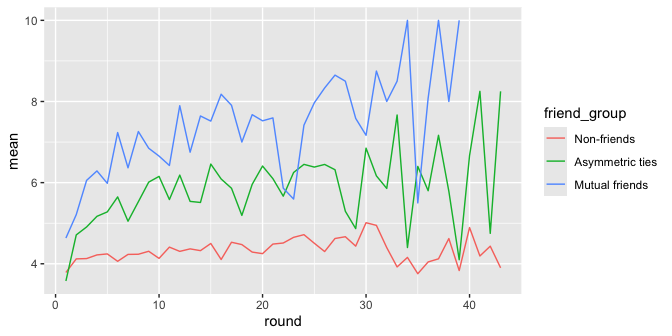

In [ ]:
# Quick look: mean tokens sent by round and friendship group
ggplot(by_round_f, aes(round, mean, color = friend_group)) +
  geom_line()

#### Supporting Information layout

Plotting code from `code/si/figures/S5_figures.R`. This is the version
saved to `output/figures/si/`.

In [ ]:
# Figure S11: the four views of Figure S10 by friendship group, with the
# overall mean as a dashed gray line.
plot_figure_s11 <- function(by_round_f, by_order_f, by_fifth_f, by_round, by_order, by_fifth) {
  # each group plus the overall mean (dashed gray)
  with_overall <- function(by_group, overall) {
    bind_rows(by_group, overall %>% mutate(friend_group = "Overall")) %>%
      mutate(friend_group = factor(friend_group, levels = names(friend_colors)))
  }

  group_panel <- function(data, x, title, xlab, ribbon = TRUE) {
    ggplot(data, aes({{ x }}, mean, color = friend_group, fill = friend_group)) +
      geom_ribbon(aes(ymin = low, ymax = high), alpha = if (ribbon) 0.12 else 0, color = NA) +
      geom_line(aes(linetype = friend_group == "Overall"), linewidth = 0.6) +
      geom_point(aes(size = classrooms)) +
      scale_color_manual(values = friend_colors, name = "Friendship nomination type") +
      scale_fill_manual(values = friend_colors, guide = "none") +
      scale_linetype_manual(values = c(`FALSE` = "solid", `TRUE` = "dashed"), guide = "none") +
      scale_size_continuous(range = c(0.3, 1.6), guide = "none") +
      labs(title = title, x = xlab, y = "Mean tokens sent") +
      theme_si(8)
  }

  figure_s11 <- (group_panel(with_overall(by_round_f, by_round), round,
                             "A. Mean tokens sent by classroom game round", "Classroom game round") +
                   coord_cartesian(ylim = c(0, 10.5)) +
                   theme(legend.position = c(0.3, 0.2), legend.title = element_text(size = 7),
                         legend.text = element_text(size = 6), legend.key.size = unit(3, "mm")) +
                   guides(color = guide_legend(ncol = 2)) |
                 group_panel(with_overall(filter(by_round_f, round <= 7), filter(by_round, round <= 7)),
                             round, "B. Common-support rounds 1-7", "Classroom game round") +
                   scale_x_continuous(breaks = 1:7)) /
                (group_panel(with_overall(by_order_f, by_order), decision_order,
                             "C. Personal decision order", "Personal decision order") +
                   geom_vline(xintercept = 6, linetype = "dotted", color = "grey60") +
                   scale_x_continuous(breaks = c(1, 6, 10, 20, 30, 38)) +
                   coord_cartesian(ylim = c(0, 10.5)) |
                 group_panel(with_overall(by_fifth_f, by_fifth), fifth,
                             "D. Personal session progress", "Personal session progress",
                             ribbon = FALSE) +
                   geom_errorbar(aes(ymin = low, ymax = high), width = 0.08) +
                   scale_x_continuous(breaks = 1:5, labels = progress_labels)) +
    plot_annotation(title = "Giving over the session by friendship nomination type",
                    theme = theme(plot.title = element_text(face = "bold", hjust = 0.5)))
  figure_s11
}

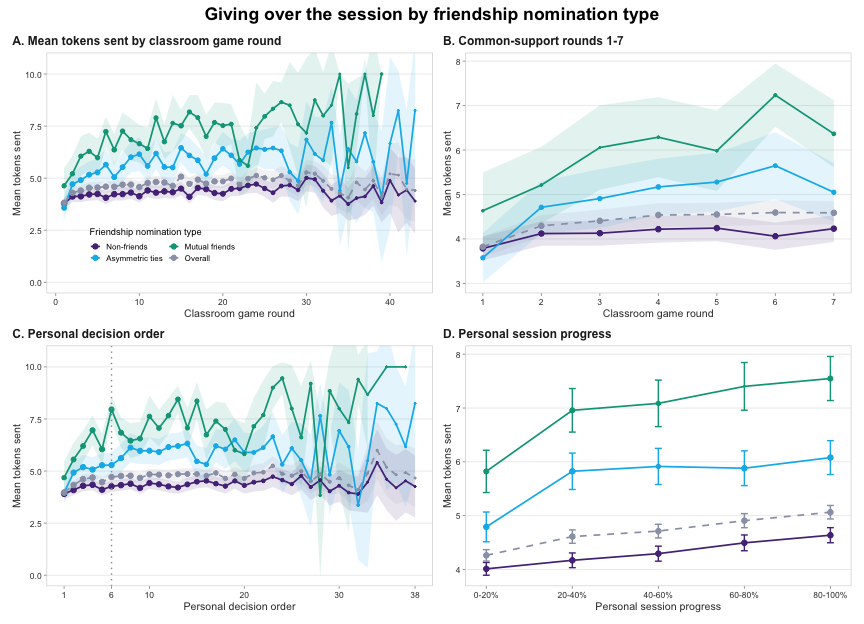

In [ ]:
# Supporting Information layout (plotting code in figures/S5_figures.R)
figure_s11 <- plot_figure_s11(by_round_f, by_order_f, by_fifth_f, by_round, by_order, by_fifth)
figure_s11

### Table S14. Giving trends by friendship group

In [ ]:
# Table S14: does giving change at the same rate in the three groups?
# tokens ~ time x group, with sender and receiver FE. Time = round - 1
# (columns 1-2) or personal progress (column 3).
dyads <- dyads %>% mutate(round_c = round - 1)

slope_models <- list(
  "All classroom rounds" = felm(tokens_sent ~ round_c * friend_group | sender_id_f + receiver_id_f | 0 | class_id, data = dyads),
  "Classroom rounds 1-7" = felm(tokens_sent ~ round_c * friend_group | sender_id_f + receiver_id_f | 0 | class_id, data = filter(dyads, round <= 7)),
  "Personal progress"    = felm(tokens_sent ~ progress * friend_group | sender_id_f + receiver_id_f | 0 | class_id, data = dyads)
)

slope_table <- imap_dfr(slope_models, function(model, name) {
  b <- coef(model)
  V <- vcov(model)
  time <- names(b)[1]
  interactions <- grep(":", names(b), value = TRUE)

  # implied slope of each group = reference slope + its interaction
  implied <- map_dfr(interactions, function(term) {
    w <- setNames(rep(0, length(b)), names(b)); w[c(time, term)] <- 1
    tibble(term = paste("Implied slope:", sub(".*friend_group", "", term)),
           estimate = sum(w * b), se = sqrt(drop(t(w) %*% V %*% w)))
  })

  # Wald test that both interactions are zero (common slope)
  wald <- lfe::waldtest(model, interactions, type = "cluster")

  summary(model)$coefficients %>%
    as_tibble(rownames = "term") %>%
    transmute(term, estimate = Estimate, se = `Cluster s.e.`) %>%
    bind_rows(implied) %>%
    bind_rows(tibble(term = c("Wald chi2(2)", "Wald p-value", "Directed allocations"),
                     estimate = c(wald[["chi2"]], wald[["p"]], model$N))) %>%
    mutate(model = name)
})

slope_table %>%
  mutate(value = if_else(is.na(se), sprintf("%.5g", estimate), sprintf("%.3f (%.3f)", estimate, se))) %>%
  select(model, term, value) %>%
  pivot_wider(names_from = model, values_from = value)

term,All classroom rounds,Classroom rounds 1-7,Personal progress
round_c,0.021 (0.007),0.044 (0.030),NA
friend_groupAsymmetric ties,0.627 (0.149),-0.065 (0.239),0.819 (0.147)
friend_groupMutual friends,1.450 (0.221),0.866 (0.296),1.565 (0.235)
round_c:friend_groupAsymmetric ties,0.035 (0.010),0.250 (0.072),NA
round_c:friend_groupMutual friends,0.069 (0.015),0.249 (0.084),NA
Implied slope: Asymmetric ties,0.056 (0.009),0.294 (0.058),1.295 (0.216)
Implied slope: Mutual friends,0.090 (0.015),0.293 (0.077),2.272 (0.355)
Wald chi2(2),21.021,17.231,17
Wald p-value,2.7248e-05,0.00018128,0.00020347
Directed allocations,17804,4704,17804


## Figure S12 and Table S15. Composition and within-child change

The rise in giving from the first to the final fifth is split into
changes within friendship groups and changes in the mix of groups. Then,
within the same children, we compare the change toward classmates they
named with the change toward the others.

### Change within friendship groups and change in group composition

In [ ]:
# Figure S12A: is the rise from the first to the final fifth due to more
# giving within each group, or to a change in the mix of groups?
first_last <- dyads %>% filter(fifth %in% c(1, 5)) %>%
  mutate(period = if_else(fifth == 1, "E", "L"))

cells <- first_last %>%
  group_by(friend_group, period) %>%
  summarise(mean = mean(tokens_sent), n = n(), .groups = "drop") %>%
  group_by(period) %>% mutate(share = n / sum(n)) %>% ungroup() %>%
  pivot_wider(id_cols = friend_group, names_from = period, values_from = c(mean, share))

decomposition <- cells %>%
  mutate(within      = (share_L + share_E) / 2 * (mean_L - mean_E),
         composition = (mean_L + mean_E) / 2 * (share_L - share_E))

decomposition

friend_group,mean_E,mean_L,share_E,share_L,within,composition
Non-friends,4.011118,4.636395,0.7783151,0.7736397,0.4852003,-0.0202152
Asymmetric ties,4.790576,6.078595,0.1458386,0.1579503,0.1956430,0.0658221
Mutual friends,5.822148,7.548262,0.0758463,0.0684099,0.1245014,-0.0497135


### Within-child comparison and bootstrap interval

In [ ]:
# Within the same child: did giving rise more toward classmates she named
# (A = mutual or sender-only) than toward the others (N)?
child_cells <- first_last %>%
  mutate(receiver_type = if_else(friendship %in% c("Mutual", "Sender declares"), "A", "N")) %>%
  group_by(class_id, sender_id, receiver_type, period) %>%
  summarise(mean_tokens = mean(tokens_sent), mean_gap = mean(rank_gap),
            share_mutual = mean(friendship == "Mutual"),
            share_receiver_only = mean(friendship == "Receiver declares"),
            decisions = n(), .groups = "drop")

# keep children observed in the four cells
complete_children <- child_cells %>% count(sender_id) %>% filter(n == 4) %>% pull(sender_id)

child_level <- child_cells %>%
  filter(sender_id %in% complete_children) %>%
  pivot_wider(id_cols = c(class_id, sender_id), names_from = c(receiver_type, period),
              values_from = c(mean_tokens, mean_gap, share_mutual, share_receiver_only)) %>%
  transmute(class_id, sender_id,
            change_A = mean_tokens_A_L - mean_tokens_A_E,
            change_N = mean_tokens_N_L - mean_tokens_N_E,
            D        = change_A - change_N,
            d_gap_A  = mean_gap_A_L - mean_gap_A_E,
            d_gap_N  = mean_gap_N_L - mean_gap_N_E,
            d_mutual_A        = share_mutual_A_L - share_mutual_A_E,
            d_receiver_only_N = share_receiver_only_N_L - share_receiver_only_N_E)

c(children = nrow(child_level), classrooms = n_distinct(child_level$class_id),
  change_A = mean(child_level$change_A), change_N = mean(child_level$change_N),
  D = mean(child_level$D))
##    children  classrooms    change_A    change_N           D 
## 216.0000000  43.0000000   1.6126543   0.8967482   0.7159061

within_child_models <- function(data) {
  list(lm(D ~ 1, data = data),
       lm(D ~ d_gap_A + d_gap_N, data = data),
       lm(D ~ d_gap_A + d_gap_N + d_mutual_A + d_receiver_only_N, data = data))
}

# Classroom bootstrap: resample classrooms with replacement (4,999 times),
# keeping each child's four cells together
set.seed(4999)
classrooms <- unique(child_level$class_id)
bootstrap <- map_dfr(1:4999, function(b) {
  sampled <- tibble(class_id = sample(classrooms, replace = TRUE)) %>%
    left_join(child_level, by = "class_id", relationship = "many-to-many")
  fits <- within_child_models(sampled)
  tibble(draw = b, mean_D = mean(sampled$D),
         model = 1:3, intercept = map_dbl(fits, ~ coef(.x)[1]),
         coefficients = map(fits, coef))
})

bootstrap %>% filter(model == 1) %>%
  summarise(ci_low = quantile(mean_D, 0.025), ci_high = quantile(mean_D, 0.975))

ci_low,ci_high
0.1190267,1.345972


### Table S15. Within-child regression estimates

In [ ]:
table_s15 <- map2_dfr(within_child_models(child_level), 1:3, function(fit, m) {
  draws <- bootstrap %>% filter(model == m) %>% pull(coefficients) %>% do.call(rbind, .)
  tibble(model = m, term = names(coef(fit)), estimate = coef(fit),
         bootstrap_se = apply(draws, 2, sd),
         ci_low = apply(draws, 2, quantile, 0.025), ci_high = apply(draws, 2, quantile, 0.975),
         r2 = summary(fit)$r.squared)
})

table_s15 %>% mutate(across(where(is.double), ~ round(.x, 3)))

model,term,estimate,bootstrap_se,ci_low,ci_high,r2
1,(Intercept),0.716,0.314,0.119,1.346,0.000
2,(Intercept),0.726,0.314,0.115,1.339,0.011
2,d_gap_A,-0.356,0.957,-2.168,1.572,0.011
2,d_gap_N,2.350,1.680,-1.007,5.661,0.011
3,(Intercept),0.758,0.328,0.128,1.406,0.024
3,d_gap_A,-0.331,0.958,-2.140,1.600,0.024
3,d_gap_N,2.521,1.706,-0.901,5.839,0.024
3,d_mutual_A,0.678,0.488,-0.223,1.696,0.024
3,d_receiver_only_N,1.257,1.284,-1.546,3.575,0.024


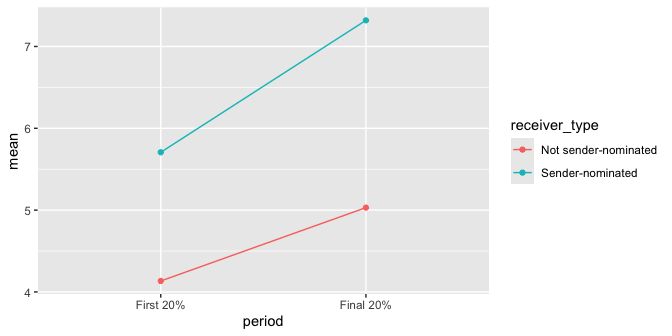

In [ ]:
# Figure S12: (A) aggregate change and its two components; (B) mean giving
# of the same children toward the classmates they named and the others, in the
# first and final fifths; (C) the within-child changes with classroom-bootstrap CIs
# within-child means (first and final fifth) toward nominated (A) and other (N) classmates
child_means <- child_cells %>%
  filter(sender_id %in% complete_children) %>%
  group_by(receiver_type, period) %>%
  summarise(mean = mean(mean_tokens), se = sd(mean_tokens) / sqrt(n()), .groups = "drop") %>%
  mutate(receiver_type = if_else(receiver_type == "A", "Sender-nominated", "Not sender-nominated"),
         period = if_else(period == "E", "First 20%", "Final 20%"),
         period = factor(period, levels = c("First 20%", "Final 20%")))

# classroom bootstrap of the three child-level means
set.seed(999)
change_draws <- map_dfr(1:999, function(b) {
  sampled <- tibble(class_id = sample(classrooms, replace = TRUE)) %>%
    left_join(child_level, by = "class_id", relationship = "many-to-many")
  tibble(reference = mean(sampled$change_N), additional = mean(sampled$D), total = mean(sampled$change_A))
})

change_components <- tibble(
  term = factor(c("Reference\n(not sender-\nnominated)", "Additional\nchange toward\nnominated",
                  "Total change\ntoward\nnominated"),
                levels = rev(c("Reference\n(not sender-\nnominated)", "Additional\nchange toward\nnominated",
                               "Total change\ntoward\nnominated"))),
  estimate = c(mean(child_level$change_N), mean(child_level$D), mean(child_level$change_A)),
  low  = map_dbl(change_draws, quantile, 0.025),
  high = map_dbl(change_draws, quantile, 0.975),
  highlight = c(FALSE, TRUE, FALSE))

# Quick look: giving toward named and other classmates, first and final fifth
ggplot(child_means, aes(period, mean, color = receiver_type, group = receiver_type)) +
  geom_line() +
  geom_point()

#### Supporting Information layout

Plotting code from `code/si/figures/S5_figures.R`. This is the version
saved to `output/figures/si/`.

In [ ]:
# Figure S12, panel A: aggregate change in mean giving and its two components.
plot_s12_panel_a <- function(decomposition, n_children) {
  group_colors <- friend_colors[c("Non-friends", "Asymmetric ties", "Mutual friends")]
  overall_change <- sum(decomposition$within + decomposition$composition)

  components <- decomposition %>%
    select(friend_group, `Category means` = within, `Category shares` = composition) %>%
    pivot_longer(-friend_group, names_to = "component") %>%
    mutate(friend_group = factor(friend_group, levels = c("Asymmetric ties", "Non-friends", "Mutual friends")))

  component_totals <- components %>% group_by(component) %>% summarise(total = sum(value)) %>%
    add_row(component = "Overall\nchange", total = overall_change) %>%
    mutate(component = factor(component, levels = c("Category shares", "Category means", "Overall\nchange")))

  figure_s12_a <- ggplot() +
    geom_col(data = filter(component_totals, component == "Overall\nchange"),
             aes(total, component), fill = color_slate, width = 0.5) +
    geom_col(data = components, aes(value, factor(component, levels = levels(component_totals$component)),
                                    fill = friend_group), width = 0.5) +
    geom_text(data = filter(components, component == "Category means"),
              aes(value, component, label = sprintf("%.3f", value), group = friend_group),
              position = position_stack(vjust = 0.5), color = "white", size = 2.2, fontface = "bold") +
    geom_point(data = component_totals, aes(total, component), size = 1) +
    geom_text(data = component_totals, aes(total, component, label = sprintf("%+.3f", total)),
              hjust = -0.3, size = 2.4) +
    geom_vline(xintercept = 0, linetype = "dashed", color = "grey50") +
    scale_fill_manual(values = group_colors) +
    scale_x_continuous(limits = c(-0.1, 1.05)) +
    scale_y_discrete(limits = c("Category shares", "Category means", "Overall\nchange")) +
    labs(title = "A. Aggregate change components",
         subtitle = sprintf("%s children | 45 classrooms | Equal weight per decision", n_children),
         x = "Change in mean tokens sent", y = NULL) +
    theme_si(8) + theme(panel.grid.major.y = element_blank())
  figure_s12_a
}

In [ ]:
# Figure S12, panel B: giving of the same children toward the classmates
# they named and toward the others, first and final fifth of the session.
plot_s12_panel_b <- function(child_means, child_level) {
  figure_s12_b <- ggplot(child_means, aes(period, mean, color = receiver_type, group = receiver_type)) +
    geom_line(aes(linetype = receiver_type)) +
    geom_errorbar(aes(ymin = mean - 1.96 * se, ymax = mean + 1.96 * se), width = 0.06) +
    geom_point(aes(shape = receiver_type), size = 2, fill = "white") +
    scale_color_manual(values = c("Sender-nominated" = color_highlight, "Not sender-nominated" = color_slate), name = NULL) +
    scale_linetype_manual(values = c("Sender-nominated" = "solid", "Not sender-nominated" = "dashed"), name = NULL) +
    scale_shape_manual(values = c("Sender-nominated" = 16, "Not sender-nominated" = 21), name = NULL) +
    labs(title = "B. Giving within the same children",
         subtitle = sprintf("%d children | %d classrooms | Equal weight per child",
                            nrow(child_level), n_distinct(child_level$class_id)),
         x = "Personal session progress", y = "Mean tokens sent") +
    theme_si(8) + theme(legend.position = c(0.65, 0.12))
  figure_s12_b
}

In [ ]:
# Figure S12, panel C: within-child changes with classroom-bootstrap 95% CIs.
plot_s12_panel_c <- function(change_components, child_level) {
  figure_s12_c <- ggplot(change_components, aes(estimate, term, color = highlight)) +
    geom_vline(xintercept = 0, linetype = "dashed", color = "grey50") +
    geom_errorbarh(aes(xmin = low, xmax = high), height = 0.15) +
    geom_point(size = 1.8) +
    geom_text(aes(x = high, label = sprintf("%+.2f", estimate)), hjust = -0.2, size = 2.4) +
    scale_color_manual(values = c(`FALSE` = "grey20", `TRUE` = color_highlight)) +
    scale_x_continuous(expand = expansion(mult = c(0.05, 0.15))) +
    labs(title = "C. Within-child change components",
         subtitle = sprintf("%d children | First vs. final 20%% of personal session progress", nrow(child_level)),
         x = "Mean within-child change (tokens)", y = NULL) +
    theme_si(8) + theme(panel.grid.major.y = element_blank())
  figure_s12_c
}

In [ ]:
# Figure S12: the three panels side by side
plot_figure_s12 <- function(decomposition, child_means, change_components, child_level, n_children) {
  plot_s12_panel_a(decomposition, n_children) |
    plot_s12_panel_b(child_means, child_level) |
    plot_s12_panel_c(change_components, child_level)
}

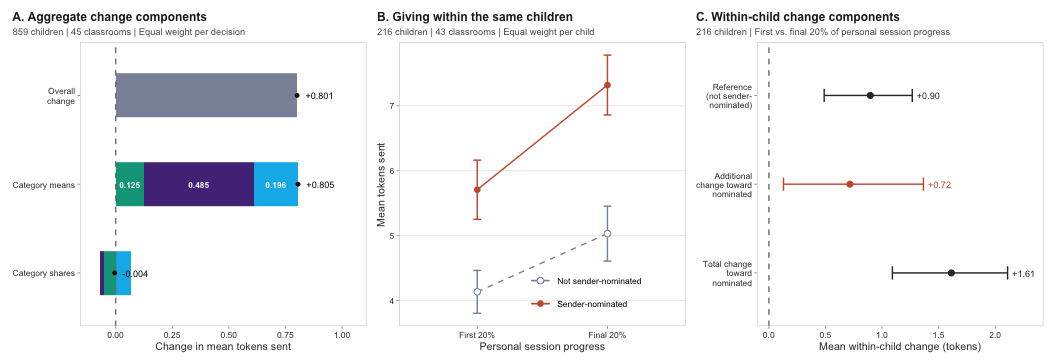

In [ ]:
# Supporting Information layout (plotting code in figures/S5_figures.R)
figure_s12 <- plot_figure_s12(decomposition, child_means, change_components, child_level,
                              n_children = n_distinct(dyads$sender_id))
figure_s12

## Figure S13. Classroom size

In [ ]:
# Figure S13: by classroom size group, and classroom-specific slopes
size_groups <- dyads %>%
  mutate(size_group = cut(class_size, c(0, 15, 21, 39), labels = c("Small (7-15)", "Medium (16-21)", "Large (22-39)"))) %>%
  mean_ci(fifth, size_group)

class_slopes <- dyads %>%
  group_by(class_id, class_size) %>%
  group_modify(~ tibble(slope = coef(felm(tokens_sent ~ progress | sender_id_f + receiver_id_f, data = .x))[["progress"]])) %>%
  ungroup()

cor.test(class_slopes$slope, class_slopes$class_size)
## 
##  Pearson's product-moment correlation
## 
## data:  class_slopes$slope and class_slopes$class_size
## t = 0.65834, df = 43, p-value = 0.5138
## alternative hypothesis: true correlation is not equal to 0
## 95 percent confidence interval:
##  -0.1994899  0.3822199
## sample estimates:
##        cor 
## 0.09989352

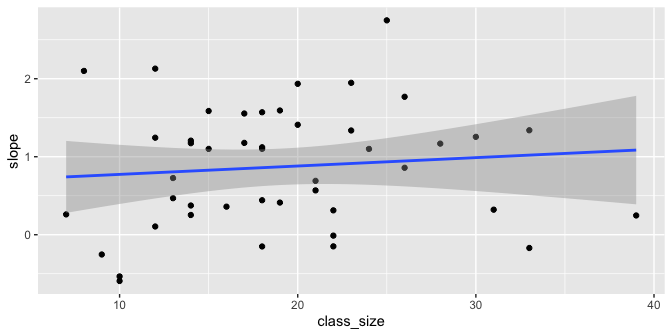

In [ ]:
# Quick look: classroom-specific trends against classroom size
ggplot(class_slopes, aes(class_size, slope)) +
  geom_point() +
  geom_smooth(method = "lm")

#### Supporting Information layout

Plotting code from `code/si/figures/S5_figures.R`. This is the version
saved to `output/figures/si/`.

In [ ]:
# Figure S13: (A) giving over the session by classroom size; (B) classroom-
# specific trends against classroom size.
plot_figure_s13 <- function(size_groups, class_slopes) {
  size_colors <- c("Small (7-15)" = "#5BA4B5", "Medium (16-21)" = "#2E7F8C", "Large (22-39)" = "#173F45")

  figure_s13 <- (ggplot(size_groups, aes(fifth, mean, color = size_group)) +
                   geom_ribbon(aes(ymin = low, ymax = high, fill = size_group), alpha = 0.15, color = NA) +
                   geom_line() + geom_point(size = 1.2) +
                   scale_color_manual(values = size_colors, name = NULL) +
                   scale_fill_manual(values = size_colors, guide = "none") +
                   scale_x_continuous(breaks = 1:5, labels = progress_labels) +
                   labs(title = "A. Personal session progress by classroom size",
                        x = "Personal session progress", y = "Mean tokens sent") +
                   theme_si(8) + theme(legend.position = c(0.75, 0.15))) |
                (ggplot(class_slopes, aes(class_size, slope)) +
                   geom_hline(yintercept = 0, linetype = "dashed", color = "grey50") +
                   geom_smooth(method = "lm", color = color_highlight, fill = color_highlight,
                               alpha = 0.15, linewidth = 0.6) +
                   geom_point(color = color_slate) +
                   labs(title = "B. Classroom-specific trends and class size",
                        x = "Participants in classroom", y = "First-to-last change in tokens sent") +
                   theme_si(8))
  figure_s13 <- figure_s13 +
    plot_annotation(title = "Temporal sending patterns and classroom size",
                    theme = theme(plot.title = element_text(face = "bold", hjust = 0.5)))
  figure_s13
}

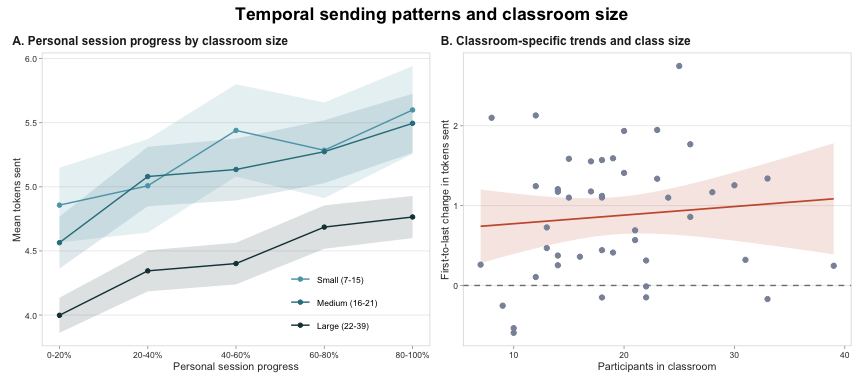

In [ ]:
# Supporting Information layout (plotting code in figures/S5_figures.R)
figure_s13 <- plot_figure_s13(size_groups, class_slopes)
figure_s13

## Figure S14. Time between decisions

Only the 29 classrooms where the tablets recorded the time of each
decision.

In [ ]:
# Figure S14: seconds between two consecutive decisions of the same child,
# in the 29 classrooms where the time of each decision was recorded
intervals <- dyads %>%
  filter(!is.na(seconds_since_start)) %>%
  group_by(sender_id) %>%
  arrange(decision_order, .by_group = TRUE) %>%
  mutate(seconds = seconds_since_start - lag(seconds_since_start),
         decile  = pmin(pmax(ceiling(progress * 10), 1), 10)) %>%
  ungroup() %>%
  filter(!is.na(seconds))

c(intervals = nrow(intervals), children = n_distinct(intervals$sender_id),
  classrooms = n_distinct(intervals$class_id), median = median(intervals$seconds))
##  intervals   children classrooms     median 
##      10740        544         29         44

pacing <- intervals %>%
  group_by(decile) %>%
  summarise(median = median(seconds), q25 = quantile(seconds, 0.25), q75 = quantile(seconds, 0.75))

pacing

decile,median,q25,q75
1,65,45,108.00
2,54,34,85.00
3,48,33,69.00
4,44,31,68.25
5,41,28,61.00
6,42,29,72.00
7,44,30,62.00
8,38,28,58.00
9,40,28,64.00
10,40,28,63.00


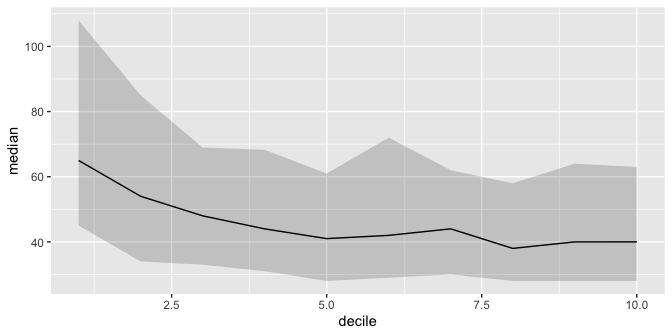

In [ ]:
# Quick look: median interval (and interquartile range) by decile of the session
ggplot(pacing, aes(decile, median)) +
  geom_ribbon(aes(ymin = q25, ymax = q75), alpha = 0.2) +
  geom_line()

#### Supporting Information layout

Plotting code from `code/si/figures/S5_figures.R`. This is the version
saved to `output/figures/si/`.

In [ ]:
plot_figure_s14 <- function(intervals) {
  # Figure S14: median interval (and interquartile range) by decile of the
  # child's decision sequence, for all decisions and by relationship
  pacing_by_group <- bind_rows(
    intervals %>% mutate(panel = "A. All relations"),
    intervals %>% mutate(panel = c("Non-friends" = "B. Non-friends", "Asymmetric ties" = "C. Asymmetric ties",
                                   "Mutual friends" = "D. Mutual friends")[as.character(friend_group)])
  ) %>%
    group_by(panel, decile) %>%
    summarise(median = median(seconds), q25 = quantile(seconds, 0.25), q75 = quantile(seconds, 0.75),
              .groups = "drop")

  panel_colors <- c("A. All relations" = color_slate, "B. Non-friends" = color_non_friends,
                    "C. Asymmetric ties" = color_asymmetric, "D. Mutual friends" = color_mutual)
  decile_labels <- paste0((0:9) * 10, "-", (1:10) * 10)

  figure_s14 <- ggplot(pacing_by_group, aes(decile, median, color = panel, fill = panel)) +
    geom_ribbon(aes(ymin = q25, ymax = q75), alpha = 0.18, color = NA) +
    geom_line(linewidth = 0.7) + geom_point(size = 1) +
    facet_wrap(~ panel, ncol = 2) +
    scale_color_manual(values = panel_colors) + scale_fill_manual(values = panel_colors) +
    scale_x_continuous(breaks = 1:10, labels = decile_labels) +
    scale_y_continuous(limits = c(0, 125), breaks = seq(0, 120, 20)) +
    labs(title = "Decision pacing over the session", x = "Within-session progress decile (%)",
         y = "Interval (seconds)") +
    theme_si(8) +
    theme(plot.title = element_text(hjust = 0.5), plot.title.position = "panel",
          axis.text.x = element_text(angle = 45, hjust = 1, size = 6))
  figure_s14
}

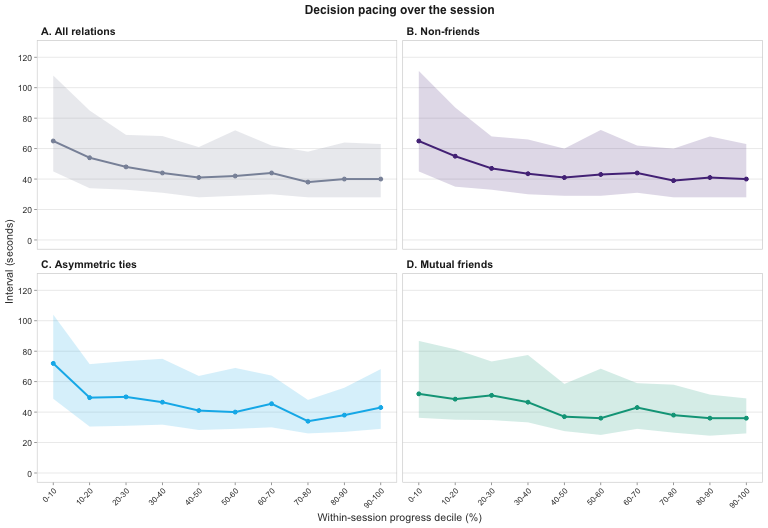

In [ ]:
# Supporting Information layout (plotting code in figures/S5_figures.R)
figure_s14 <- plot_figure_s14(intervals)
figure_s14

In [ ]:
save_table(table_s11_a, "S5_table_s11a_schedule")
save_table(table_s11_b, "S5_table_s11b_temporal_models")
save_table(table_s12, "S5_table_s12_game")
save_table(coverage, "S5_table_s13_coverage")
save_table(slope_table, "S5_table_s14_friendship_slopes")
save_table(decomposition, "S5_decomposition")
save_table(table_s15, "S5_table_s15_within_child")
save_table(pacing, "S5_pacing")
save_si_figure(figure_s9,  "S5_figure_s9_game",           9, 7)
save_si_figure(figure_s10, "S5_figure_s10_time",          9, 6)
save_si_figure(figure_s11, "S5_figure_s11_time_friendship", 9, 6.5)
save_si_figure(figure_s12, "S5_figure_s12_decomposition", 11, 3.8)
save_si_figure(figure_s13, "S5_figure_s13_class_size",    9, 4)
save_si_figure(figure_s14, "S5_figure_s14_pacing",        8, 5.5)